# Unidad 3 · Práctica 1 — La forma de scikit-learn

Ciencia de Datos · UTN FRM · 2026

Esta es la primera de las tres clases prácticas de la unidad. Se corre **de arriba hacia
abajo**: cada sección usa lo que dejaron las anteriores.

De la Unidad 2 traés un dataset auditado y una tabla de columnas candidatas. Acá lo convertimos
en el primer modelo entrenado. Pero el tema de la clase no es el modelo: es **cómo está armada
la librería** con la que vas a trabajar el resto de la unidad. Si entendés su forma, los
modelos que vienen después son un cambio de una línea.

## Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | El problema: qué se predice, qué no puede estar, contra qué se compara | `X`, `y`, la partición y el piso |
| **2** | Las tres interfaces: `fit`, `transform`, `predict` | saber leer —y escribir— cualquier objeto de la librería |
| **3** | Composición: `Pipeline` y `ColumnTransformer` | la receta completa, en un objeto |
| **4** | El primer modelo, y su lectura honesta | un clasificador entrenado y sus límites |
| **5** | Interpretabilidad: qué aprendió y en qué se apoya | poder explicar el modelo sin mostrar código |
| **6** | El puente al proyecto propio | qué llevar a la Entrega 3 |

## Antes de empezar

Hace falta `fifa_canonico_2026-07-23.csv`, el mismo archivo de la Unidad 2: 18.936 jugadores y
90 columnas, producido por el DAG `fifa_ingest`. La primera celda lo baja sola la primera vez
que corrés el notebook.

In [ ]:
# El dataset se baja del Drive de la cátedra la primera vez que se corre el notebook
import os

ARCHIVO  = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

df = pd.read_csv(ARCHIVO, low_memory=False)
df.shape

(18936, 90)

## Parte 1 — El problema: qué predecimos y contra qué lo comparamos

Antes de la primera línea de scikit-learn hay tres cosas que decidir, y ninguna es técnica:
qué columna es la respuesta, qué columnas **no pueden estar**, y contra qué número vamos a
decir que un modelo «anda bien». Las tres se deciden mirando los datos, y las tres se vuelven
a decidir en tu proyecto integrador.

### 1.1 La variable objetivo

`best_position` es la posición en la que sofifa considera que el jugador rinde mejor. Ya la
usamos en la Unidad 2 —era el agrupador de las hipótesis de η²— y es la que vamos a predecir.
Empecemos por mirar cómo viene.

<Axes: xlabel='best_position'>

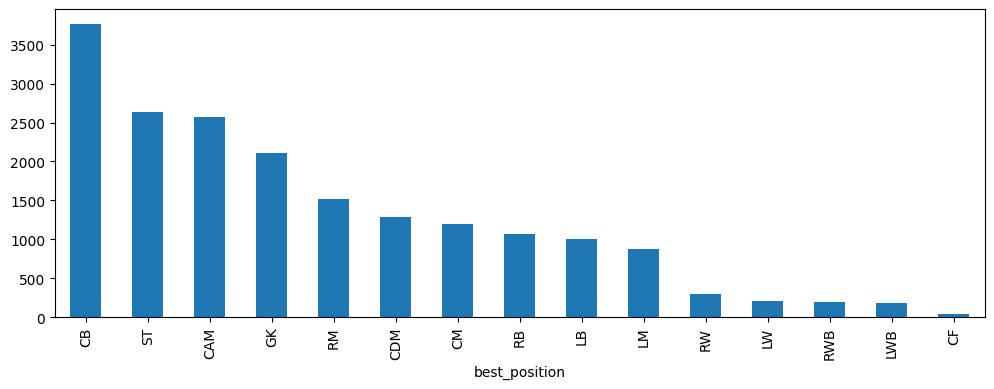

In [ ]:
# la columna que vamos a predecir, tal como viene
df["best_position"].value_counts().plot.bar(figsize=(12, 4))

Quince clases y muy desparejas: `CB` tiene 3.769 jugadores y `CF` tiene 40. Una clase de 40
filas no se aprende ni se evalúa —en una partición del 20 % quedan ocho jugadores de prueba, y
acertar uno más o uno menos mueve cualquier métrica—. Para esta clase agrupamos las quince
posiciones en los siete roles del fútbol. Con las quince clases crudas la clase chica manda, y no
hay mucho que un modelo pueda hacer con cuarenta filas; se puede probar, pero no es lo que vamos a
hacer ni acá ni en el TP3.

In [ ]:
# de las quince posiciones de sofifa a los siete roles
GRUPO = {"GK": "Arquero",
         "CB": "Defensor central",
         "LB": "Lateral",  "RB": "Lateral",  "LWB": "Lateral", "RWB": "Lateral",
         "CDM": "Volante defensivo",
         "CM": "Volante",  "CAM": "Volante", "LM": "Volante",  "RM": "Volante",
         "LW": "Extremo",  "RW": "Extremo",
         "ST": "Delantero", "CF": "Delantero"}

y = df["best_position"].map(GRUPO)

<Axes: xlabel='best_position'>

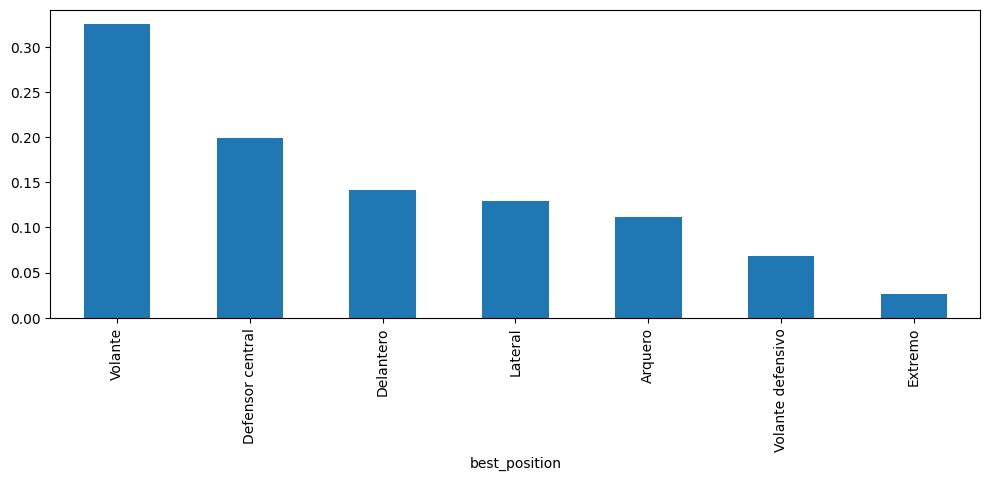

In [ ]:
# cuánto pesa cada rol
y.value_counts(normalize=True).plot.bar(figsize=(12, 4))

Sigue desparejo —Volante se lleva un tercio del dataset y Extremo no llega al 3 %— pero ahora
todas las clases tienen con qué entrenarse. Ese **0,325 de Volante** va a reaparecer en un
minuto, y no es casualidad.

### 1.2 Las columnas que no pueden estar

En la Unidad 2, la hipótesis H5 se llamaba «`player_positions` es la mejor columna que
tenemos» y terminaba en un veredicto: es **fuga**. Una columna con fuga es la que no existiría
en el momento de predecir, o la que trae la respuesta escrita de otra forma. Se mide, no se
sospecha: comparemos la primera posición que lista `player_positions` contra el rol que
queremos predecir.

In [ ]:
# la primera posición listada, traducida al mismo vocabulario de siete roles
primera = df["player_positions"].str.split(",").str[0].str.strip().map(GRUPO)
(primera == y).mean().round(4)

np.float64(0.8725)

In [ ]:
# cómo son los casos en los que no coinciden
df.loc[primera != y, ["short_name", "player_positions", "best_position"]].head()

,short_name,player_positions,best_position
1,A. Şimşir,"LW, LM, ST",CAM
12,T. Delaney,"CDM, CM",CB
21,K. Arnstad,"LW, CM, LM",CAM
29,T. Bech,"RW, RM",CAM
41,C. Yirenkyi,"CM, CB, RB, CDM",CDM


El 87 % de las veces son la misma cosa, y el 13 % restante son jugadores polifuncionales, donde
la primera de la lista no es la mejor. Un modelo que reciba esa columna no aprende a leer un
jugador: aprende a copiar. `club_position` cae por lo mismo —dice dónde lo pone el técnico— y
`best_overall` también, porque sofifa lo calcula **usando** `best_position`. Las tres salen, y
con ellas los identificadores, las URLs y los nombres, que no son fuga pero tampoco información.

In [ ]:
# lo que sacamos y por qué
FUGA = ["best_position",      # es la respuesta
        "player_positions",   # la contiene el 87% de las veces
        "club_position",      # dice dónde juega hoy
        "best_overall"]       # sofifa lo calcula usando best_position

IDS = ["player_id", "short_name", "long_name", "player_url", "player_face_url",
       "club_team_id", "club_name", "nationality_id", "nationality_name",
       "league_id", "league_name", "league_country", "fifa_version", "fifa_update",
       "fifa_update_date", "club_joined_date", "club_loan_end_date",
       "club_jersey_number", "club_contract_valid_until_year", "player_traits"]

X = df.drop(columns=FUGA + IDS)
X.shape

(18936, 66)

In [ ]:
# con qué nos quedamos: 62 numéricas y 4 categóricas
X.dtypes.value_counts()

int64    62
str       4
Name: count, dtype: int64

### 1.3 La partición

El modelo se entrena con una parte de los datos y se mide con la otra, que no vio nunca. Sin
esa separación no hay evaluación posible: un modelo que memoriza acierta el 100 % sobre lo que
memorizó.

`train_test_split` baraja las filas al azar antes de cortar. Eso tiene una consecuencia que
conviene ver antes de seguir: dos corridas de la misma línea dan dos particiones distintas.

In [ ]:
from sklearn.model_selection import train_test_split

# dos particiones seguidas, sin decir nada más: ¿cuántas filas del test coinciden?
_, test_a, _, _ = train_test_split(X, y, test_size=0.2, stratify=y)
_, test_b, _, _ = train_test_split(X, y, test_size=0.2, stratify=y)

pd.Series({"filas del test": len(test_a),
           "en común entre las dos corridas": len(set(test_a.index) & set(test_b.index))})

filas del test                     3788
en común entre las dos corridas     745
dtype: int64

Coinciden más o menos una de cada cinco, lo que se espera de dos muestras al azar del 20 %. Si se
entrena y se mide sobre cada una, los dos números van a ser parecidos pero **no iguales**, y en
tu proyecto eso se vuelve un problema real: corrés el notebook para la entrega y da 0,89; lo
corre quien corrige y da 0,90; nadie sabe si cambió algo.

Todo lo que en scikit-learn usa azar recibe un `random_state`: un número entero que fija la
secuencia aleatoria. Con el mismo número, la misma partición, todas las veces. Lo definimos una
sola vez, arriba, y lo vamos a pasar a **cada** objeto que lo acepte durante toda la unidad.

In [ ]:
SEMILLA = 42

# la misma línea dos veces, con la semilla fija: el test es idéntico
_, test_a, _, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)
_, test_b, _, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.Series({"filas del test": len(test_a),
           "en común entre las dos corridas": len(set(test_a.index) & set(test_b.index))})

filas del test                     3788
en común entre las dos corridas    3788
dtype: int64

`stratify=y` es la otra decisión de la línea: mantiene la proporción de cada rol en las dos
partes. Con Extremo al 2,6 %, sin estratificar una partición al azar puede dejar el test con la
mitad de extremos que el train, y la comparación deja de significar algo.

Una advertencia que se cobra en la Práctica 2: la semilla hace que el número sea **repetible**,
no que sea verdad. El 0,90 que va a salir más abajo es el de *esta* partición; con otra semilla
podría ser 0,89 o 0,91, y medir cuánto se mueve es un tema entero.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.Series({"entrenamiento": len(X_train), "prueba": len(X_test)})

entrenamiento    15148
prueba            3788
dtype: int64

In [ ]:
# la estratificación mantuvo las proporciones
pd.DataFrame({"train": y_train.value_counts(normalize=True),
              "test":  y_test.value_counts(normalize=True)}).round(3)

,train,test
best_position,,
Volante,0.325,0.325
Defensor central,0.199,0.199
Delantero,0.142,0.141
Lateral,0.129,0.129
Arquero,0.111,0.111
Volante defensivo,0.068,0.068
Extremo,0.026,0.026


### 1.4 El piso

Antes de entrenar nada hay que saber **contra qué se compara**. Un modelo que contesta siempre
«Volante», sin mirar una sola columna, acierta el 32,5 % de las veces. Ese es el piso: un
clasificador que dé 40 % no es bueno, es apenas mejor que no pensar.

`DummyClassifier` existe para eso, y de paso nos muestra los dos únicos verbos que vamos a
usar durante toda la unidad.

In [ ]:
from sklearn.dummy import DummyClassifier

piso = DummyClassifier(strategy="most_frequent")
piso.fit(X_train, y_train)
round(piso.score(X_test, y_test), 4)

0.325

El piso queda en **0,325**, exactamente el peso de la clase más grande. Guardalo: es el número
contra el que hay que leer todo lo que viene.

## Parte 2 — Las tres interfaces

scikit-learn no es una colección de algoritmos: es una colección de objetos que cumplen **el
mismo contrato**. Un árbol de decisión, un normalizador, un PCA y un k-means no se parecen en
nada por dentro, y se usan igual por fuera.

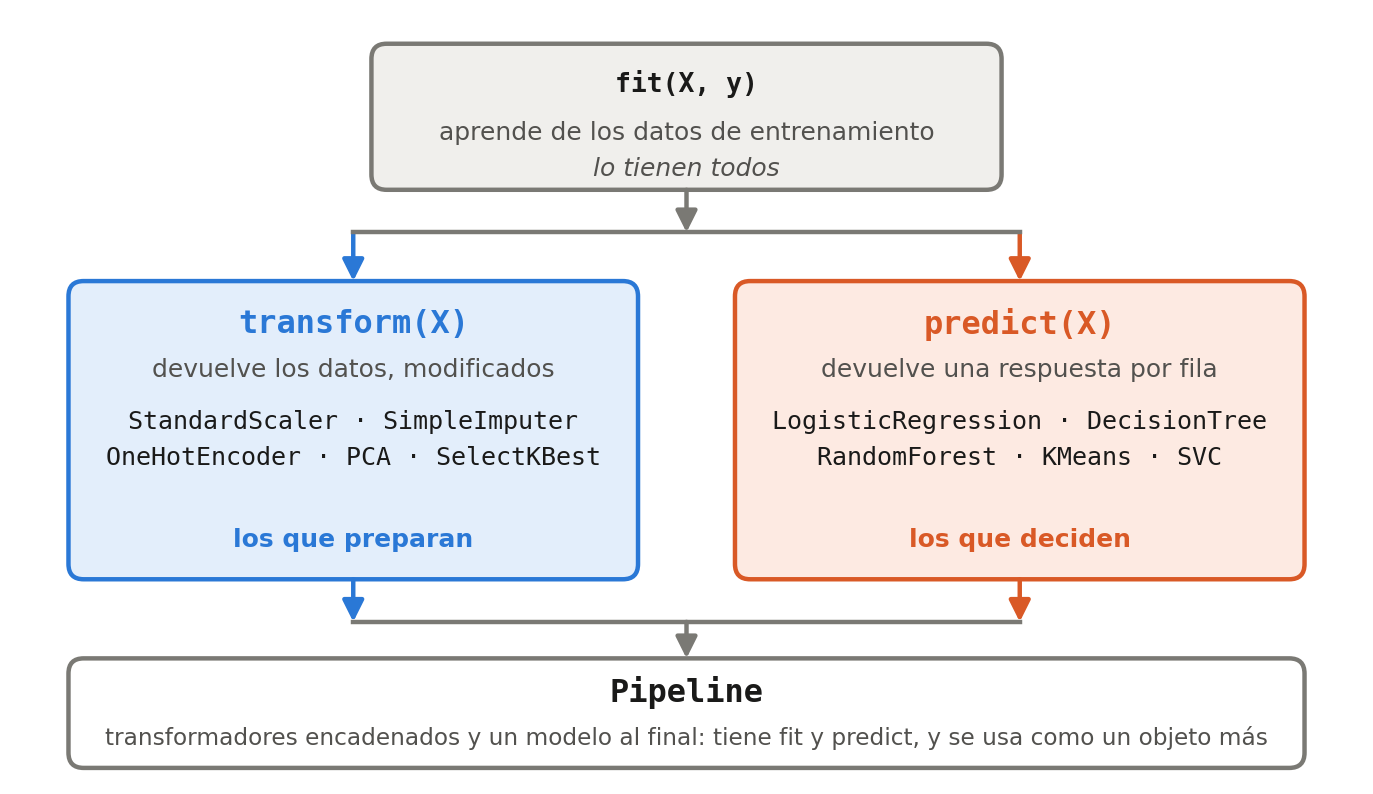

Todo lo demás es una consecuencia de esos tres verbos. Los que preparan aprenden en `fit` y
aplican en `transform`; los que deciden aprenden en `fit` y contestan en `predict`. Y un objeto
puede tener los dos verbos de abajo: un pipeline entero, por ejemplo.

### 2.1 Todo empieza con fit

Un objeto de scikit-learn se **instancia** con sus hiperparámetros —lo que vos elegís— y
después se **entrena** con `fit`. `get_params()` lista lo primero: todo lo que pusiste, o dejaste
por omisión, en el constructor.

Para las próximas demostraciones usamos un puñado de columnas, sin preparar. Feo a propósito:
la preparación es el tema de la Parte 3.

In [ ]:
from sklearn.linear_model import LogisticRegression

CHICAS = ["age", "height_cm", "weight_kg", "pace", "shooting",
          "passing", "dribbling", "defending", "physic"]

modelo = LogisticRegression(max_iter=1000)
pd.Series(modelo.get_params())

C                           1.0
class_weight               None
dual                      False
fit_intercept              True
intercept_scaling             1
l1_ratio                    0.0
max_iter                   1000
n_jobs                     None
penalty              deprecated
random_state               None
solver                    lbfgs
tol                      0.0001
verbose                       0
warm_start                False
dtype: object

In [ ]:
# antes del fit no existe ningún atributo aprendido
hasattr(modelo, "coef_")

False

In [ ]:
modelo.fit(X_train[CHICAS], y_train)
hasattr(modelo, "coef_")

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


True

El aviso de convergencia que tira la celda no es un error y conviene leerlo: el optimizador se
quedó sin iteraciones porque las columnas están en escalas muy distintas —la edad va de 16 a 45
y el valor de mercado a millones—. Es el primer argumento a favor de la Parte 3.

### 2.2 Qué aprendió: los atributos con guión bajo

`get_params` muestra lo que elegiste. Del otro lado está lo que el objeto **aprendió**, y la
librería lo marca con una convención tipográfica: los atributos que nacen del `fit` terminan en
guión bajo. No hay un `get_learned_params`, pero se listan igual, porque son atributos comunes
del objeto.

In [ ]:
def aprendidos(estimador):
    '''Lista los atributos que el objeto aprendió en fit: los que terminan en guión bajo.'''
    filas = []
    for nombre, valor in vars(estimador).items():
        if nombre.endswith("_") and not nombre.startswith("_"):
            forma = getattr(valor, "shape", "")
            filas.append((nombre, type(valor).__name__, str(forma)))
    return pd.DataFrame(filas, columns=["atributo", "tipo", "forma"])

In [ ]:
# lo que aprendió nuestra regresión
aprendidos(modelo)

,atributo,tipo,forma
0,feature_names_in_,ndarray,"(9,)"
1,n_features_in_,int,
2,classes_,ndarray,"(7,)"
3,n_iter_,ndarray,"(1,)"
4,coef_,ndarray,"(7, 9)"
5,intercept_,ndarray,"(7,)"


`coef_` tiene forma (7, 9): un juego de nueve pesos por cada uno de los siete roles. `classes_`
guarda el orden de las clases —el que después usan `predict_proba` y la matriz de confusión— y
`n_iter_` cuántas iteraciones necesitó el optimizador. Nada de eso se eligió: se aprendió.

La misma función sirve para cualquier objeto de la librería, y es la forma más rápida de
contestar «¿qué guarda esto adentro?».

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

aprendidos(StandardScaler().fit(X_train[CHICAS]))

,atributo,tipo,forma
0,feature_names_in_,ndarray,"(9,)"
1,n_features_in_,int,
2,n_samples_seen_,float64,()
3,mean_,ndarray,"(9,)"
4,var_,ndarray,"(9,)"
5,scale_,ndarray,"(9,)"


In [ ]:
aprendidos(SimpleImputer(strategy="median").fit(X_train[CHICAS]))

,atributo,tipo,forma
0,feature_names_in_,ndarray,"(9,)"
1,n_features_in_,int,
2,indicator_,NoneType,
3,statistics_,ndarray,"(9,)"


In [ ]:
aprendidos(DecisionTreeClassifier(max_depth=3).fit(X_train[CHICAS], y_train))

,atributo,tipo,forma
0,feature_names_in_,ndarray,"(9,)"
1,n_features_in_,int,
2,n_outputs_,int,
3,classes_,ndarray,"(7,)"
4,n_classes_,int64,()
5,max_features_,int,
6,tree_,Tree,


Tres objetos, tres cosas aprendidas completamente distintas: el escalador guarda una media y un
desvío por columna, el imputador guarda una mediana por columna, y el árbol guarda un objeto
`tree_` que es la estructura de preguntas entera. Y los tres se entrenaron con la misma llamada.

`feature_names_in_` y `n_features_in_` aparecen en los tres: son el registro de con qué forma de
datos se entrenó, y es lo que permite que el objeto se queje si después le pasás otra cosa.

### 2.3 El mismo verbo, modelos que no se parecen en nada

Acá está el punto de toda la clase. Una regresión logística ajusta pesos; un árbol parte el
espacio con preguntas; k-vecinos no aprende nada y compara contra los datos guardados; naive
Bayes multiplica probabilidades. Cuatro ideas incompatibles entre sí, y **el mismo código**.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

candidatos = {"regresión logística": LogisticRegression(max_iter=1000),
              "árbol de decisión":   DecisionTreeClassifier(max_depth=6, random_state=SEMILLA),
              "k vecinos":           KNeighborsClassifier(),
              "naive Bayes":         GaussianNB()}

In [ ]:
# el mismo bucle sirve para los cuatro
pd.Series({nombre: m.fit(X_train[CHICAS], y_train).score(X_test[CHICAS], y_test)
           for nombre, m in candidatos.items()}).round(3)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


regresión logística    0.811
árbol de decisión      0.725
k vecinos              0.810
naive Bayes            0.711
dtype: float64

Ninguno de los cuatro sabe que existen los otros, y sin embargo el bucle no tiene un solo `if`.
Esa es la propiedad que vas a usar todo el tiempo: **probar otro modelo cuesta cambiar una
línea**, así que la pregunta deja de ser «¿cómo se usa este algoritmo?» y pasa a ser «¿cuál
elijo, y con qué criterio?». La Práctica 2 es entera sobre esa segunda pregunta.

### 2.4 Los que transforman

La otra mitad de la librería no decide nada: prepara. Un `StandardScaler` lleva cada columna a
media 0 y desvío 1. Aprende en `fit` —la media y el desvío de cada columna, como vimos en
2.2— y aplica en `transform`.

In [ ]:
# las escalas con las que arrancamos
X_train[CHICAS].describe().loc[["mean", "std"]].round(2)

,age,height_cm,weight_kg,pace,shooting,passing,dribbling,defending,physic
mean,24.67,182.07,75.11,68.20,53.88,58.09,63.1,50.04,64.36
std,4.83,6.91,6.87,9.95,13.70,9.80,9.2,16.56,9.56


In [ ]:
escalador = StandardScaler().fit(X_train[CHICAS])
pd.Series(escalador.mean_, index=CHICAS).round(2)

age           24.67
height_cm    182.07
weight_kg     75.11
pace          68.20
shooting      53.88
passing       58.09
dribbling     63.10
defending     50.04
physic        64.36
dtype: float64

In [ ]:
# lo que sale de transform: las mismas columnas, en otra escala
pd.DataFrame(escalador.transform(X_train[CHICAS]), columns=CHICAS).describe().loc[["mean", "std"]].round(2)

,age,height_cm,weight_kg,pace,shooting,passing,dribbling,defending,physic
mean,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Las nueve medias y los nueve desvíos se calcularon **sobre el entrenamiento**. Esa elección es
la que hace posible el error de la sección que sigue.

### 2.5 El error que conviene ver una vez

El contrato tiene una trampa. El `fit` va sólo sobre el entrenamiento —si el escalador mirara
el test, el modelo estaría usando información que no debería tener— pero el `transform` va
sobre **las dos partes**. Escalás el train, entrenás, y si al momento de predecir te olvidás de
escalar el test, el modelo recibe números en otra escala y contesta cualquier cosa.

In [ ]:
lg = LogisticRegression(max_iter=1000)
lg.fit(escalador.transform(X_train[CHICAS]), y_train)

pd.Series({"test transformado":    lg.score(escalador.transform(X_test[CHICAS]), y_test),
           "test sin transformar": lg.score(X_test[CHICAS], y_test)}).round(3)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


test transformado       0.819
test sin transformar    0.309
dtype: float64

De 0,82 a 0,31 por dos líneas olvidadas. Y lo peor es que no falla: no hay excepción, no hay
mensaje de error, el modelo contesta con total naturalidad.

La Parte 3 existe para que ese olvido sea **imposible**.

### 2.6 Cuántos objetos cumplen este contrato

Podría ser una convención de unas pocas clases centrales. No lo es: la librería expone un
registro de todo lo que respeta el contrato, y se puede contar.

In [ ]:
from sklearn.utils import all_estimators

censo = pd.DataFrame([(n, c.__module__.split(".")[1]) for n, c in all_estimators()],
                     columns=["clase", "modulo"])
len(censo)

208

In [ ]:
# cuántos hay de cada tipo
pd.Series({t: len(all_estimators(type_filter=t))
           for t in ["classifier", "regressor", "transformer", "cluster"]})

classifier     44
regressor      55
transformer    84
cluster        12
dtype: int64

Más de doscientos objetos, y ninguno inventa una forma nueva de usarse. Los clasificadores y
los regresores se usan con `fit` y `predict`; los transformadores, con `fit` y `transform`; los
agrupadores —los de la Práctica 3— con `fit` y `predict` también, pero sin `y`. Lo que cambia
entre uno y otro es lo que hacen por dentro, nunca cómo se los llama.

Pero las cuentas no cierran: los cuatro tipos suman menos que el total del censo. Hay objetos que
no entran en ninguno de los cuatro filtros, y se pueden listar.

In [ ]:
# los que no entran en ninguno de los cuatro tipos
en_algun_tipo = set().union(*(set(n for n, _ in all_estimators(type_filter=t))
                              for t in ["classifier", "regressor", "transformer", "cluster"]))
fuera = sorted(set(censo["clase"]) - en_algun_tipo)

pd.Series({"total del censo": len(censo), "en alguno de los cuatro tipos": len(en_algun_tipo),
           "en ninguno": len(fuera)})

total del censo                  208
en alguno de los cuatro tipos    181
en ninguno                        27
dtype: int64

In [ ]:
# quiénes son
censo.set_index("clase").loc[fuera, "modulo"].sort_values()

clase
SpectralBiclustering                  cluster
SpectralCoclustering                  cluster
GraphicalLassoCV                   covariance
MinCovDet                          covariance
LedoitWolf                         covariance
ShrunkCovariance                   covariance
GraphicalLasso                     covariance
OAS                                covariance
EmpiricalCovariance                covariance
EllipticEnvelope                   covariance
IsolationForest                      ensemble
CountVectorizer            feature_extraction
TfidfVectorizer            feature_extraction
FrozenEstimator                        frozen
SGDOneClassSVM                   linear_model
SpectralEmbedding                    manifold
MDS                                  manifold
ClassicalMDS                         manifold
BayesianGaussianMixture               mixture
GaussianMixture                       mixture
RandomizedSearchCV            model_selection
GridSearchCV                

Las tres familias grandes no rompen el contrato: lo estiran.

- **Detección de anomalías** —`IsolationForest`, `OneClassSVM`, `LocalOutlierFactor`,
  `EllipticEnvelope`— tienen `fit` y `predict`, pero `predict` devuelve 1 o −1 (normal o raro) y
  no necesitan `y`. No son clasificadores porque no aprenden clases: aprenden qué es lo normal.
- **Densidad y covarianza** —`KernelDensity`, `GaussianMixture`, `EmpiricalCovariance` y los de
  `covariance`— aprenden en `fit` y contestan con `score_samples`: cuán probable es cada fila.
- **Los contenedores** —`Pipeline`, `GridSearchCV`, `RandomizedSearchCV`— son estimadores porque
  envuelven a otro estimador y le prestan su interfaz. `Pipeline` es la Parte 3 de hoy; los otros
  dos, la Práctica 2.

Quedan unos pocos sueltos —los vectorizadores de texto, `NearestNeighbors`, los de `manifold`—
que tienen `fit` y algún verbo propio de su tarea. Y en la otra dirección hay objetos que cuentan
en **dos** tipos a la vez: `KMeans` es agrupador y transformador, porque además de asignar un
grupo puede devolver la distancia a cada centro. Por eso los cuatro tipos suman más que la
cantidad de objetos que entran en alguno.

In [ ]:
# dónde vive cada familia
censo["modulo"].value_counts().head(12)

modulo
linear_model            37
preprocessing           19
ensemble                18
cluster                 14
decomposition           14
feature_selection       11
neighbors               11
covariance               8
feature_extraction       7
svm                      7
manifold                 6
kernel_approximation     5
Name: count, dtype: int64

In [ ]:
# cuatro ejemplos de cada tipo
pd.DataFrame({t: [n for n, _ in all_estimators(type_filter=t)[:4]]
              for t in ["classifier", "regressor", "transformer", "cluster"]})

,classifier,regressor,transformer,cluster
0,AdaBoostClassifier,ARDRegression,AdditiveChi2Sampler,AffinityPropagation
1,BaggingClassifier,AdaBoostRegressor,BernoulliRBM,AgglomerativeClustering
2,BernoulliNB,BaggingRegressor,Binarizer,Birch
3,CalibratedClassifierCV,BayesianRidge,Birch,BisectingKMeans


In [ ]:
# la familia que vamos a usar en la Práctica 2
censo.loc[censo["modulo"] == "ensemble", "clase"].tolist()

['AdaBoostClassifier',
 'AdaBoostRegressor',
 'BaggingClassifier',
 'BaggingRegressor',
 'ExtraTreesClassifier',
 'ExtraTreesRegressor',
 'GradientBoostingClassifier',
 'GradientBoostingRegressor',
 'HistGradientBoostingClassifier',
 'HistGradientBoostingRegressor',
 'IsolationForest',
 'RandomForestClassifier',
 'RandomForestRegressor',
 'RandomTreesEmbedding',
 'StackingClassifier',
 'StackingRegressor',
 'VotingClassifier',
 'VotingRegressor']

Ese listado es, básicamente, el programa de la unidad. `ensemble` es la Práctica 2 —bosques y
boosting—; `cluster` y `decomposition` son la Práctica 3 —k-means y PCA—; `feature_selection`
y `preprocessing` son lo que estamos armando hoy. Cuando en la teórica aparezca un modelo
nuevo, la pregunta práctica va a ser una sola: **en qué módulo vive y qué le pongo en el
constructor**. El resto ya lo sabés.

### 2.7 Escribir tu propio transformador

Tu proyecto integrador va a necesitar un paso que la librería no trae: una columna derivada
de tu dominio, una regla de limpieza propia, una forma de imputar que no existe. Ese paso tiene
que vivir **adentro** del pipeline —si lo hacés en una celda aparte, reaparece el problema de la
sección 2.5—, así que hay que escribirlo con la forma de scikit-learn.

Para el ejemplo usamos tres columnas nuevas que restan habilidades entre sí: `defending` menos
`shooting`, `physic` menos `dribbling`, `passing` menos `dribbling`. La idea es que el **contraste**
entre dos habilidades dice más del rol que cada una por separado: un defensor y un delantero pueden
tener el mismo `overall`, pero el signo de `defending - shooting` los separa.

Y le damos al paso **un hiperparámetro propio**, `relativo`: si está en `True`, cada resta se divide
por el `overall` del jugador. Una diferencia de 20 puntos no significa lo mismo en un jugador de 50
que en uno de 90, y dividir la convierte en una proporción. No sabemos todavía cuál de las dos
versiones anda mejor —eso se decide en la Práctica 2—, y justamente por eso va como hiperparámetro:
es lo que se elige en el constructor, como el `C` de la regresión logística en la sección 2.1.

La librería da el molde. Son dos clases base de las que se hereda, más los dos verbos que se
escriben a mano, más un método que dice cómo se llaman las columnas que salen:

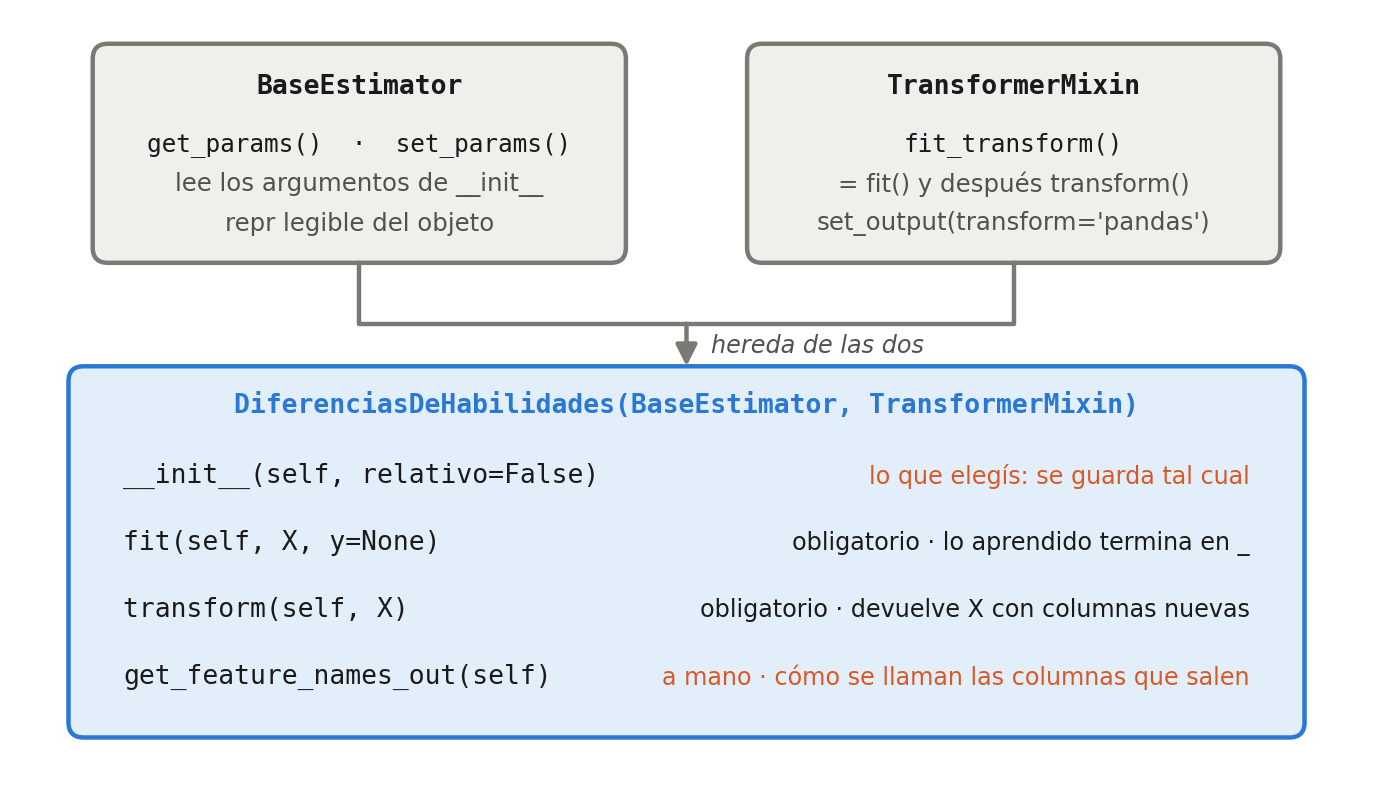

Dos reglas que la librería impone: en `__init__` sólo se **guardan** los argumentos, con el mismo
nombre y sin tocarlos —`get_params` los lee de ahí—, y todo lo que se aprende en `fit` se guarda
con guión bajo al final, como en la sección 2.2.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

DERIVADAS = ["def_menos_ata", "fisico_menos_tecnica", "pase_menos_gambeta"]

class DiferenciasDeHabilidades(BaseEstimator, TransformerMixin):
    '''Agrega tres columnas que restan habilidades entre sí.

    relativo=True las divide por el overall, para que midan perfil y no nivel.
    '''

    def __init__(self, relativo=False):
        self.relativo = relativo          # se guarda tal cual: get_params lo lee de acá

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)   # lo aprendido, con guión bajo
        return self                                      # fit siempre devuelve self

    def transform(self, X):
        nuevas = pd.DataFrame({"def_menos_ata":        X["defending"] - X["shooting"],
                               "fisico_menos_tecnica": X["physic"]    - X["dribbling"],
                               "pase_menos_gambeta":   X["passing"]   - X["dribbling"]},
                              index=X.index)
        if self.relativo:
            nuevas = nuevas.div(X["overall"], axis=0)
        return pd.concat([X, nuevas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, DERIVADAS])

In [ ]:
# los dos verbos, uno después del otro
DiferenciasDeHabilidades().fit(X_train).transform(X_train.head(3))[DERIVADAS]

,def_menos_ata,fisico_menos_tecnica,pase_menos_gambeta
14910,-3,11,-3
1687,-49,-14,-10
5228,-1,-2,-7


In [ ]:
# el hiperparámetro cambia lo que sale: las mismas tres restas, divididas por el overall
pd.concat({"relativo=False": DiferenciasDeHabilidades().fit(X_train).transform(X_train.head(3))[DERIVADAS],
           "relativo=True":  DiferenciasDeHabilidades(relativo=True).fit(X_train).transform(X_train.head(3))[DERIVADAS].round(3)},
          axis=1)

relativo=False                                         relativo=True                                        
       def_menos_ata fisico_menos_tecnica pase_menos_gambeta def_menos_ata fisico_menos_tecnica pase_menos_gambeta
14910             -3                   11                 -3        -0.043                0.157             -0.043
1687             -49                  -14                -10        -0.590               -0.169             -0.120
5228              -1                   -2                 -7        -0.013               -0.027             -0.093

Funciona en las dos versiones, y con eso ya se puede meter en un `Pipeline`. Lo que no es obvio es qué aportan las dos
clases base, porque nada de lo que escribimos las usa. Se mide comparando contra la misma clase
**sin heredar de nada**: mismos `fit` y `transform`, y nada más.

In [ ]:
class SinHeredar:
    def __init__(self, relativo=False): self.relativo = relativo
    def fit(self, X, y=None):           return self
    def transform(self, X):             return X

def que_tiene(objeto):
    return {"fit_transform":  hasattr(objeto, "fit_transform"),
            "get_params":     hasattr(objeto, "get_params"),
            "cómo se imprime": repr(objeto).split(" at ")[0]}

pd.DataFrame({"sin heredar":  que_tiene(SinHeredar(relativo=True)),
              "con las dos":  que_tiene(DiferenciasDeHabilidades(relativo=True))})

,sin heredar,con las dos
fit_transform,False,True
get_params,False,True
cómo se imprime,<__main__.SinHeredar object,DiferenciasDeHabilidades(relativo=True)


`TransformerMixin` regala `fit_transform`, que arma llamando a los dos métodos que sí escribiste.
`BaseEstimator` regala `get_params` —leyendo los argumentos de tu `__init__`— y un `repr` que
muestra los hiperparámetros en vez de una dirección de memoria.

Lo segundo es lo que importa: sin `get_params`, tu paso es una caja negra para el pipeline, que no
puede listar ni cambiar su `relativo`. En la sección 3.5 vas a ver cómo lo lista, y en la Práctica 2
la búsqueda de hiperparámetros va a depender de eso. Sin herencia anda hoy y se rompe en tres
semanas.

## Parte 3 — Composición

Con tres interfaces alcanza para armar cualquier cosa, y el motivo es que **los objetos que las
cumplen se meten unos adentro de otros**. Un pipeline de tres transformadores y un modelo es,
él mismo, un objeto con `fit` y `predict`: se puede pasar a otra función que espere un modelo,
o meter adentro de otro pipeline.

### 3.1 Pipeline: una sola cosa en vez de cuatro

`Pipeline` recibe una lista de pasos con nombre. Al hacer `fit` los recorre en orden llamando
`fit_transform` en cada uno, y `fit` en el último. Al hacer `predict` aplica el `transform` de
todos y el `predict` del último — **siempre**, sobre cualquier dato que le pases.

El objeto se suele llamar *pipe*, y así lo vas a ver en la documentación y en cualquier código
ajeno.

In [ ]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([("imputar", SimpleImputer(strategy="median")),
                 ("escalar", StandardScaler()),
                 ("modelo",  LogisticRegression(max_iter=1000))])

pipe.fit(X_train[CHICAS], y_train)
round(pipe.score(X_test[CHICAS], y_test), 3)

0.819

Es el mismo 0,82 de la sección 2.5, y ahora el olvido de la línea siguiente no existe: no hay
forma de predecir sin transformar, porque son la misma llamada.

### 3.2 El pipeline es, a su vez, un estimador

Esta es la propiedad que cierra el círculo. Preguntémosle a tres objetos distintos qué métodos
tienen.

In [ ]:
objetos = {"StandardScaler": StandardScaler(),
           "LogisticRegression": LogisticRegression(),
           "Pipeline entero": pipe}

pd.DataFrame({n: {v: hasattr(o, v) for v in ["fit", "transform", "predict"]}
              for n, o in objetos.items()})

,StandardScaler,LogisticRegression,Pipeline entero
fit,True,True,True
transform,True,False,False
predict,False,True,True


El pipeline tiene `fit` y `predict`: para cualquier función de la librería es un modelo más.
Por eso en la Práctica 2 vamos a poder pasarle el pipeline **entero** a la validación cruzada y
a la búsqueda de hiperparámetros, y todo lo que hay adentro se va a reentrenar en cada
partición sin que tengamos que ocuparnos.

### 3.3 ColumnTransformer: dos ramas para dos tipos de columna

Un problema queda: las 62 columnas numéricas se imputan con la mediana y se escalan, pero las 4
categóricas —`preferred_foot`, `body_type`, `real_face`, `acceleration_type`— no se pueden
escalar, hay que convertirlas en columnas de ceros y unos. `ColumnTransformer` aplica un
pipeline distinto a cada grupo de columnas y pega los resultados.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

NUMERICAS   = X.select_dtypes("number").columns.tolist()
CATEGORICAS = [c for c in X.columns if c not in NUMERICAS]

CATEGORICAS

['preferred_foot', 'body_type', 'real_face', 'acceleration_type']

In [ ]:
# cuántos valores distintos tiene cada categórica
X[CATEGORICAS].nunique()

preferred_foot        2
body_type            10
real_face             2
acceleration_type     5
dtype: int64

`OneHotEncoder` aprende en `fit` la lista de valores distintos de cada columna, y en `transform`
reemplaza cada columna por **una columna nueva por valor**: un 1 en la del valor que tiene la fila
y 0 en las demás. Tres jugadores alcanzan para verlo.

In [ ]:
codificador = OneHotEncoder(handle_unknown="ignore").fit(X_train[CATEGORICAS])

# tres jugadores, codificados: cada columna original se convierte en un bloque de ceros y un 1
pd.DataFrame(codificador.transform(X_train[CATEGORICAS].head(3)).toarray(),
             columns=codificador.get_feature_names_out(), index=X_train.index[:3]).T

,14910,1687,5228
preferred_foot_Left,1.0,0.0,1.0
preferred_foot_Right,0.0,1.0,0.0
body_type_Lean (170-),0.0,0.0,0.0
body_type_Lean (170-185),0.0,0.0,0.0
body_type_Lean (185+),0.0,0.0,0.0
body_type_Normal (170-),0.0,0.0,0.0
body_type_Normal (170-185),0.0,1.0,0.0
body_type_Normal (185+),0.0,0.0,1.0
body_type_Stocky (170-),0.0,0.0,0.0
body_type_Stocky (170-185),1.0,0.0,0.0


In [ ]:
# el efecto sobre la cantidad de columnas
pd.Series({"columnas que entran":          len(CATEGORICAS),
           "valores distintos, en total":  X[CATEGORICAS].nunique().sum(),
           "columnas que salen":           len(codificador.get_feature_names_out())})

columnas que entran             4
valores distintos, en total    19
columnas que salen             19
dtype: int64

Cuatro columnas se convierten en diecinueve, y la cuenta es exacta: la cantidad de columnas que
salen es la suma de los valores distintos que entran. `body_type` sola aporta diez. Por eso
conviene mirar `nunique()` **antes** de codificar: una columna con cientos de valores distintos
—un nombre de club, una nacionalidad— genera cientos de columnas casi vacías, y el modelo se
llena de ceros. Es una de las razones por las que los identificadores salieron en la sección 1.2.

Un detalle más: las diecinueve columnas ya están en 0 y 1, así que **no se escalan**. Ese es el
motivo de las dos ramas.

In [ ]:
preparar = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]),
     NUMERICAS + DERIVADAS),
    ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                              ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
     CATEGORICAS)])

`handle_unknown="ignore"` no es un detalle: si en el test aparece un `body_type` que no estaba
en el entrenamiento, sin esa opción el `transform` explota. Con ella, esa fila sale con ceros
en toda la rama. Es exactamente el tipo de cosa que va a pasar en tu proyecto integrador.

### 3.4 La receta completa

Todo junto: derivar las columnas nuevas, preparar cada tipo por su rama, y clasificar. Un solo
objeto, tres pasos. Lo llamamos `pipeline_completo` para no confundirlo con el clasificador que
lleva adentro: de acá en adelante, cuando decimos «el modelo» hablamos de este objeto entero, y
`clasificador` es sólo su último paso.

In [ ]:
pipeline_completo = Pipeline([("derivar",      DiferenciasDeHabilidades()),
                              ("preparar",     preparar),
                              ("clasificador", LogisticRegression(max_iter=2000))])

pipeline_completo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('derivar', ...), ('preparar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,relativo,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output

In [ ]:
# cuántas columnas le llegan finalmente al clasificador
pipeline_completo[:-1].fit_transform(X_train, y_train).shape

(15148, 84)

De 66 columnas salieron 84: las 62 numéricas más las 3 derivadas, y las 4 categóricas
convertidas en 19 columnas de ceros y unos. Ese ensanchamiento lo hizo el `OneHotEncoder`, y es
la razón por la que conviene mirar cuántos valores distintos tiene una categórica antes de
codificarla.

### 3.5 Los nombres con doble guión bajo

Un pipeline expone los parámetros de todo lo que tiene adentro, con la ruta separada por doble
guión bajo. No hace falta memorizar los nombres: se listan.

In [ ]:
# los parámetros del último paso, con su ruta completa
[p for p in pipeline_completo.get_params() if p.startswith("clasificador__")][:8]

['clasificador__C',
 'clasificador__class_weight',
 'clasificador__dual',
 'clasificador__fit_intercept',
 'clasificador__intercept_scaling',
 'clasificador__l1_ratio',
 'clasificador__max_iter',
 'clasificador__n_jobs']

In [ ]:
# y el de nuestro transformador propio, que existe porque hereda de BaseEstimator
[p for p in pipeline_completo.get_params() if p.startswith("derivar__")]

['derivar__relativo']

In [ ]:
# se pueden cambiar sin volver a escribir el pipeline
pipeline_completo.set_params(clasificador__C=0.5).get_params()["clasificador__C"]

0.5

Parece un detalle de sintaxis y es la puerta de entrada a la Práctica 2: la búsqueda de
hiperparámetros se escribe con estos nombres, y le podés pedir que pruebe a la vez el `C` del
clasificador, la estrategia del imputador que está tres niveles más adentro, y el `relativo` de
nuestra propia clase.

In [ ]:
# volvemos al valor por defecto antes de entrenar
pipeline_completo.set_params(clasificador__C=1.0)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('derivar', ...), ('preparar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,relativo,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output

## Parte 4 — El primer modelo

Ya está todo. Entrenar es una línea, y el resto de la parte es leer el resultado con
desconfianza.

### 4.1 Entrenar y medir

In [ ]:
pipeline_completo.fit(X_train, y_train)
pd.Series({"piso (contesta siempre Volante)": piso.score(X_test, y_test),
           "regresión logística":             pipeline_completo.score(X_test, y_test)}).round(3)

piso (contesta siempre Volante)    0.325
regresión logística                0.904
dtype: float64

In [ ]:
# cinco jugadores del test, con lo que contesta el modelo
pd.DataFrame({"predicho": pipeline_completo.predict(X_test.head(5)),
              "real":     y_test.head(5)}).set_index(df.loc[X_test.index[:5], "short_name"])

,predicho,real
short_name,,
M. Locatelli,Volante defensivo,Volante defensivo
T. Jacobsen,Volante,Volante defensivo
O. Brynhildsen,Volante,Delantero
F. Terry,Defensor central,Defensor central
J. Yeboah,Volante,Volante


0,90 contra un piso de 0,325. Antes de festejar, dos preguntas: ¿de dónde sale ese número, y
qué esconde?

### 4.2 La columna que sacamos

Volvamos a la fuga de la sección 1.2, ahora con un modelo en la mano. Entrenemos un
clasificador que reciba **una sola columna**: la que descartamos.

In [ ]:
solo_fuga = Pipeline([("codificar", OneHotEncoder(handle_unknown="ignore")),
                      ("clasificador", LogisticRegression(max_iter=1000))])

posicion = pd.DataFrame({"pos": df["player_positions"].str.split(",").str[0].str.strip()})
pos_train, pos_test = posicion.loc[X_train.index], posicion.loc[X_test.index]

round(solo_fuga.fit(pos_train, y_train).score(pos_test, y_test), 3)

0.879

**0,879 con una columna, contra 0,904 con sesenta y seis.** Si esa columna se hubiera quedado,
el modelo habría dado un poco mejor y no habría aprendido nada: todo el trabajo de la clase
—las habilidades, el físico, la edad— habría quedado de adorno al lado de una columna que ya
tenía la respuesta.

Esto es lo que la tabla de columnas candidatas de la Entrega 2 estaba previniendo. La última
columna de esa tabla, «¿existiría al predecir?», es la más barata de completar y la más cara de
saltear.

### 4.3 La accuracy no alcanza

Un solo número resume mal un problema de siete clases desparejas. Para ver qué esconde el 0,90
hay que cruzar lo que el modelo contestó con lo que era verdad: eso es la **matriz de confusión**.
Cada fila es un rol real, cada columna un rol predicho, y la diagonal son los aciertos.

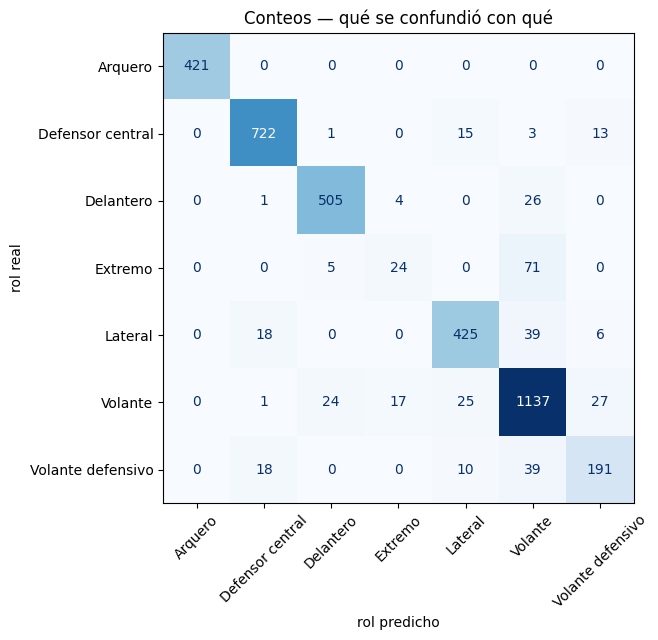

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

prediccion = pipeline_completo.predict(X_test)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y_test, prediccion, ax=ax, cmap="Blues",
                                        colorbar=False, xticks_rotation=45)
ax.set_title("Conteos — qué se confundió con qué")
ax.set_xlabel("rol predicho"); ax.set_ylabel("rol real")
plt.tight_layout()
plt.show()

Los errores no están repartidos: casi todos van a parar a la columna de Volante. Pero la fila de
Extremo casi no se ve —son 100 jugadores contra los 1.231 de Volante— y el celeste pálido invita a
ignorarla. Los conteos muestran dónde está el volumen, no dónde está el problema.

Para eso hay que **normalizar**, y hay dos formas de hacerlo que contestan preguntas distintas:

- Dividir cada **fila** por su total: de todos los jugadores que *eran* de un rol, ¿qué fracción
  recuperó el modelo? En la diagonal queda el **recall** de cada clase.
- Dividir cada **columna** por su total: de todos los jugadores que el modelo *dijo* que eran de un
  rol, ¿qué fracción lo era de verdad? En la diagonal queda la **precision**.

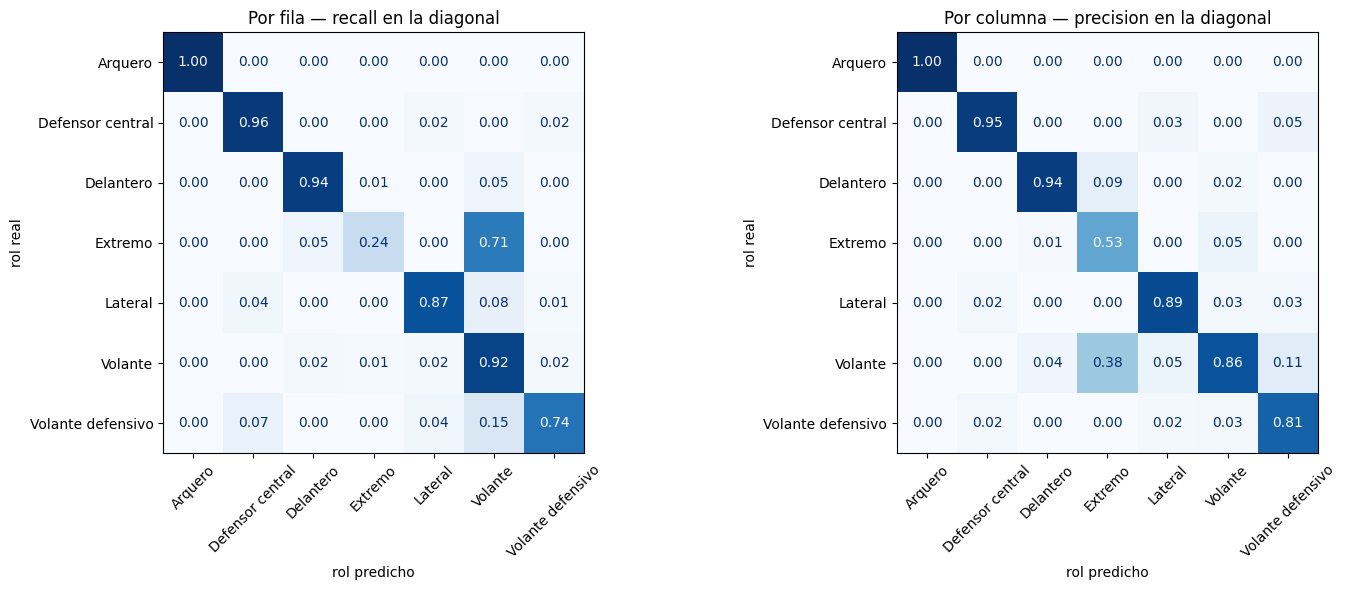

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(y_test, prediccion, ax=axes[0], cmap="Blues",
                                        colorbar=False, xticks_rotation=45,
                                        normalize="true", values_format=".2f")
axes[0].set_title("Por fila — recall en la diagonal")

ConfusionMatrixDisplay.from_predictions(y_test, prediccion, ax=axes[1], cmap="Blues",
                                        colorbar=False, xticks_rotation=45,
                                        normalize="pred", values_format=".2f")
axes[1].set_title("Por columna — precision en la diagonal")

for ax in axes:
    ax.set_xlabel("rol predicho"); ax.set_ylabel("rol real")

plt.tight_layout()
plt.show()

Ahora la fila de Extremo grita: **0,24 de recall**, y 0,71 yéndose a Volante. La matriz por
columna cuenta la otra mitad de la historia: cuando el modelo dice «Extremo» acierta 0,53 de las
veces, y el 0,38 restante eran volantes. Y la columna de Volante muestra a quién absorbe ese rol:
sobre todo volantes defensivos (0,11), y en menor medida extremos (0,05). Las dos matrices son la
misma información leída en dos direcciones, y ninguna alcanza sola: un modelo que nunca contesta
Extremo tendría precision perfecta en esa clase y recall cero.

`classification_report` resume las dos diagonales en una tabla, y agrega dos columnas: el **f1**, que
es la media armónica de precision y recall —castiga que una de las dos sea baja, así que un 0,53
y un 0,24 dan 0,33 y no 0,39—, y el **support**, cuántos jugadores reales tiene cada clase en el
test.

In [ ]:
from sklearn.metrics import classification_report

pd.DataFrame(classification_report(y_test, prediccion, output_dict=True)).T.round(3)

,precision,recall,f1-score,support
Arquero,1.000,1.000,1.000,421.000
Defensor central,0.950,0.958,0.954,754.000
Delantero,0.944,0.942,0.943,536.000
Extremo,0.533,0.240,0.331,100.000
Lateral,0.895,0.871,0.883,488.000
Volante,0.865,0.924,0.893,1231.000
Volante defensivo,0.806,0.740,0.772,258.000
accuracy,0.904,0.904,0.904,0.904
macro avg,0.856,0.811,0.825,3788.000
weighted avg,0.899,0.904,0.900,3788.000


El arquero sale en 1,00 en todo —tiene columnas propias, las de `goalkeeping_`— y el extremo en
0,33 de f1. Esa asimetría no aparece en la accuracy, porque los extremos son el 2,6 % del test:
pasar de 24 aciertos a 100 movería el número general dos puntos.

Las dos últimas filas de la tabla son dos formas de promediar. `weighted avg` pondera cada clase
por su support, así que se parece a la accuracy y esconde lo mismo. `macro avg` promedia las siete
clases **por igual**, sin importar su tamaño: el 0,33 de Extremo pesa lo mismo que el 1,00 de
Arquero, y el promedio baja a 0,825. Esa es la métrica con la que vamos a trabajar de acá en
adelante, porque es la única de la tabla que ve a la clase chica.

Regla práctica: **la de conteos para auditar, las normalizadas para decidir, y el f1 macro para
comparar modelos.**

### 4.4 Cambiar el último paso

Ahora se cobra lo de la Parte 2. Probar otro modelo es reemplazar un paso del pipeline; todo lo
demás —las derivadas, la imputación, el escalado, el one-hot— queda igual y se reentrena solo.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score

clasificadores = {"piso":                DummyClassifier(strategy="most_frequent"),
           "regresión logística": LogisticRegression(max_iter=2000),
           "árbol de decisión":   DecisionTreeClassifier(random_state=SEMILLA),
           "random forest":       RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA),
           "gradient boosting":   HistGradientBoostingClassifier(random_state=SEMILLA)}

In [ ]:
# el mismo pipeline, cambiando sólo el último paso
resultados = {}
for nombre, clasificador in clasificadores.items():
    p = pipeline_completo.set_params(clasificador=clasificador).fit(X_train, y_train)
    pred = p.predict(X_test)
    resultados[nombre] = {"accuracy": p.score(X_test, y_test),
                          "f1 por clase": f1_score(y_test, pred, average="macro")}

pd.DataFrame(resultados).T.round(3)

,accuracy,f1 por clase
piso,0.325,0.070
regresión logística,0.904,0.825
árbol de decisión,0.799,0.715
random forest,0.879,0.753
gradient boosting,0.891,0.807


Y acá aparece el resultado incómodo: **el modelo más simple gana**. La regresión logística le
saca siete puntos de f1 al random forest y casi dos al gradient boosting, que son los
modelos «mejores» de la lista. No es un error del código ni mala suerte de la semilla — es una
propiedad de este problema, y la vamos a desarmar en la Práctica 2.

Mientras tanto, quedate con la forma del experimento: cinco modelos comparados en seis líneas,
sin tocar una sola vez la preparación de los datos.

### 4.5 Lo que probamos y no anduvo

Las tres columnas derivadas de la sección 2.7 parecían una buena idea. Midámoslas en vez de
suponerlas: el mismo pipeline, con y sin el paso `derivar`.

In [ ]:
con_derivadas = pipeline_completo.set_params(clasificador=LogisticRegression(max_iter=2000)).fit(X_train, y_train)

sin_derivadas = Pipeline([("preparar", ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                                ("escalar", StandardScaler())]), NUMERICAS),
        ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
         CATEGORICAS)])),
    ("clasificador", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)

pd.Series({"con las tres derivadas": con_derivadas.score(X_test, y_test),
           "sin ellas":              sin_derivadas.score(X_test, y_test)}).round(4)

con las tres derivadas    0.9042
sin ellas                 0.9047
dtype: float64

No le sirvieron **a la regresión logística**, y el motivo es interesante: una logística ya
combina las columnas de forma lineal, así que darle `defending - shooting` no le agrega nada que
no pudiera armar sola con `defending` y `shooting`. Una columna derivada rinde cuando expresa
algo que el modelo **no puede** construir —un producto entre dos columnas, un cociente, un
umbral— o cuando el modelo no combina columnas por su cuenta.

Guardá la frase, porque en la Parte 5 la misma columna que acá no sirvió va a resultar la
pregunta más informativa de todo el dataset — para otro modelo. Y multiplicar columnas en vez de
restarlas sí mueve el número, pero para medirlo bien hace falta algo que todavía no tenemos:
es de la Práctica 2.

## Parte 5 — Interpretabilidad: qué aprendió el modelo

Un modelo que anda bien y no se puede explicar sirve para ganar una competencia y para poco más.
En la Entrega 3 no alcanza con mostrar una métrica: hay que poder decir **en qué se apoya** el
modelo, y si eso tiene sentido en el dominio. Esta parte son tres formas de contestarlo, de la
más pegada al modelo a la más independiente de él.

### 5.1 Los coeficientes: qué empuja hacia cada clase

En la sección 2.2 vimos que la logística aprende un `coef_` con un peso por columna para cada rol.
Con los nombres de las columnas —que existen porque nuestro transformador implementa
`get_feature_names_out`— eso se lee como una tabla de 7 filas por 84 columnas.

Lo que importa de cada peso es su **magnitud y su signo**: un peso grande y positivo empuja al
jugador hacia ese rol, uno grande y negativo lo aleja, y uno cercano a cero no participa. Por eso
para cada rol miramos las columnas de mayor **valor absoluto**, no las de mayor valor.

Dos condiciones hacen que los números sean comparables entre sí: las columnas están
**estandarizadas**, así que un peso grande significa un efecto grande y no una unidad chica; y los
valores son **relativos entre clases**, porque la logística multinomial reparte la probabilidad
entre los siete roles.

In [ ]:
nombres = [n.split("__")[-1] for n in pipeline_completo[:-1].get_feature_names_out()]
coeficientes = pd.DataFrame(pipeline_completo[-1].coef_, index=pipeline_completo[-1].classes_, columns=nombres)
coeficientes.shape

(7, 84)

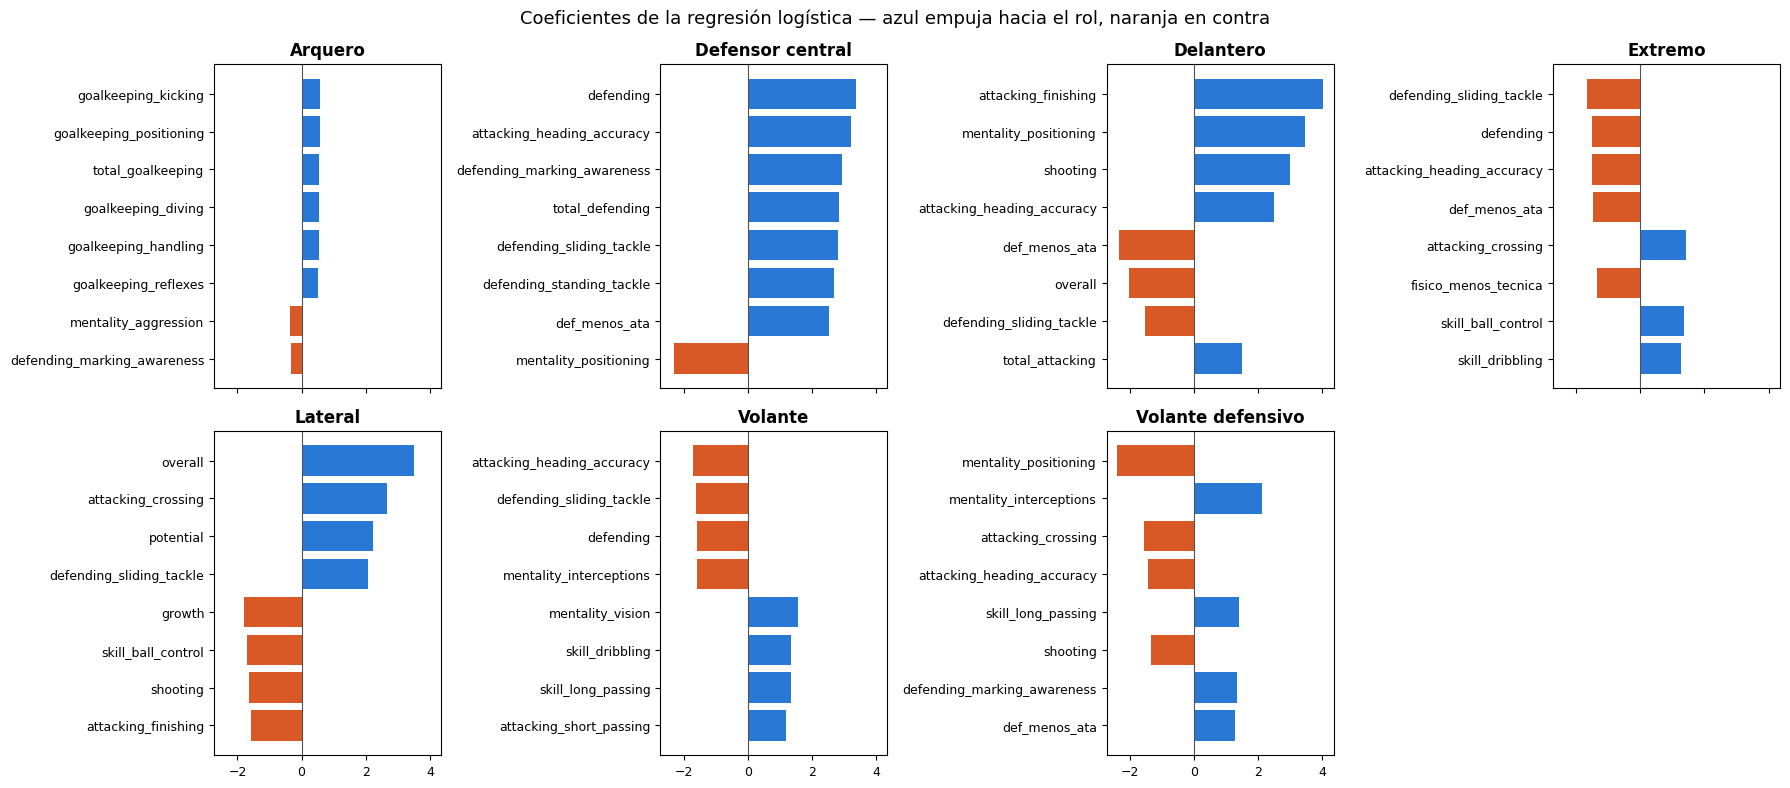

In [ ]:
# por rol, las ocho columnas de mayor peso absoluto, con su signo
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, (rol, fila) in zip(axes.flat, coeficientes.iterrows()):
    top = fila.reindex(fila.abs().nlargest(8).index[::-1])   # la de mayor peso absoluto arriba
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2a78d6", "#d95926"))
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(rol, fontsize=12, weight="bold")
    ax.tick_params(labelsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Coeficientes de la regresión logística — azul empuja hacia el rol, naranja en contra", fontsize=13)
plt.tight_layout()
plt.show()

Los paneles se leen solos, y eso es la mejor señal de que el modelo aprendió algo razonable. Al
defensor central lo definen `defending`, el cabezazo y el quite, y lo aleja `mentality_positioning`,
que es una habilidad de atacante. Al delantero, la definición y el posicionamiento, y lo alejan
`def_menos_ata` —nuestra columna derivada— y el quite. Al volante defensivo, las intercepciones y el
pase largo; al volante, la visión y el pase corto, con todo lo defensivo en contra.

El panel de **Extremo** es el que hay que mirar dos veces. Lo empujan el centro, el control y la
gambeta; lo alejan defender, el quite y el cabezazo. El modelo tiene el concepto correcto —eso es
un extremo— y aun así recupera uno de cada cuatro. El problema no es que le falte la idea: es que
tiene 499 jugadores contra 6.153 volantes, y eso se arregla en la Práctica 2, no con más columnas.

Dos cosas más que valen una discusión en clase:

- **Arquero** tiene seis barras casi iguales y chicas, todas de `goalkeeping_`. No es que importen
  poco: son seis columnas que dicen lo mismo, y la logística repartió el peso entre ellas. Guardá
  esto para la sección 5.5.
- **Lateral** se apoya en `overall` y `potential` a favor y en `growth` en contra, y no hay historia
  futbolística que lo explique. En un modelo multinomial un coeficiente puede estar compensando a
  otra clase en vez de describiendo a la propia. Conviene desconfiar antes de inventar una
  explicación.

### 5.2 El modelo que se lee sin ayuda

Hay una familia de modelos cuya interpretación no requiere tablas: se dibuja. Un árbol de tres
niveles sobre el mismo pipeline pierde casi veinte puntos de accuracy contra la logística, y a cambio
se puede leer en voz alta.

In [ ]:
from sklearn.tree import plot_tree

arbol = pipeline_completo.set_params(clasificador=DecisionTreeClassifier(max_depth=3, random_state=SEMILLA))
arbol.fit(X_train, y_train)
round(arbol.score(X_test, y_test), 3)

0.725

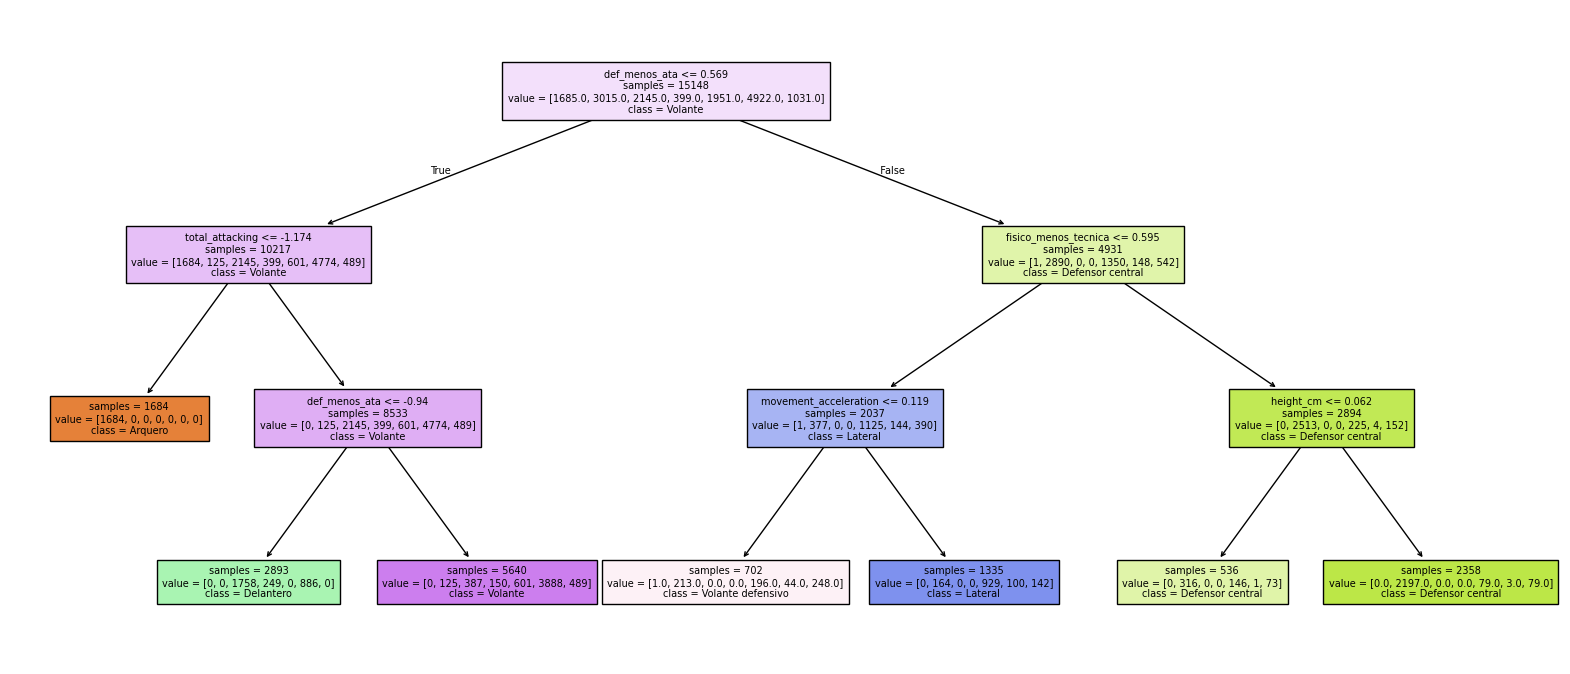

In [ ]:
fig, ax = plt.subplots(figsize=(20, 8.5))
plot_tree(arbol[-1], feature_names=nombres, class_names=arbol[-1].classes_,
          filled=True, impurity=False, fontsize=7, ax=ax)
plt.show()

Mirá la pregunta de la raíz: **`def_menos_ata`**, la columna derivada que en la sección 4.5 no le
había servido de nada a la regresión logística. Para el árbol es la pregunta más informativa de
las 84 — y no es la única: de las seis preguntas que hace el árbol, **tres son columnas que
inventamos nosotros**. El motivo es exactamente el que anticipamos: un árbol no puede restar dos
columnas, sólo puede poner umbrales a una por vez, así que una resta que le venga hecha le
resuelve de entrada la separación entre quien defiende y quien ataca.

La misma columna, inútil para un modelo y la mejor para otro. Eso es lo que quiere decir que la
ingeniería de variables **depende del modelo**, y es el argumento más concreto contra el
«agreguemos features y veamos».

### 5.3 Los ensambles: importancia por impureza

¿Y los dos modelos que perdieron en la sección 4.4? Un random forest son cientos de árboles como el
de arriba, pero sin límite de profundidad, y la respuesta es la votación de todos. Ninguno se puede
dibujar.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

bosque = pipeline_completo.set_params(clasificador=RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA))
bosque.fit(X_train, y_train)

# cuántos árboles, y qué tamaño tiene el primero
primero = bosque[-1].estimators_[0]
pd.Series({"árboles": len(bosque[-1].estimators_),
           "profundidad del primero": primero.get_depth(),
           "hojas del primero": primero.get_n_leaves()})

árboles                     300
profundidad del primero      30
hojas del primero          1477
dtype: int64

Lo que sí se puede hacer es contar. Cada árbol, en cada pregunta, reduce la mezcla de clases de
sus nodos —la *impureza*—, y la librería anota cuánto de esa reducción se debe a cada columna.
Promediado sobre los trescientos árboles, eso es `feature_importances_`: un número por columna,
todos positivos, que suman 1.

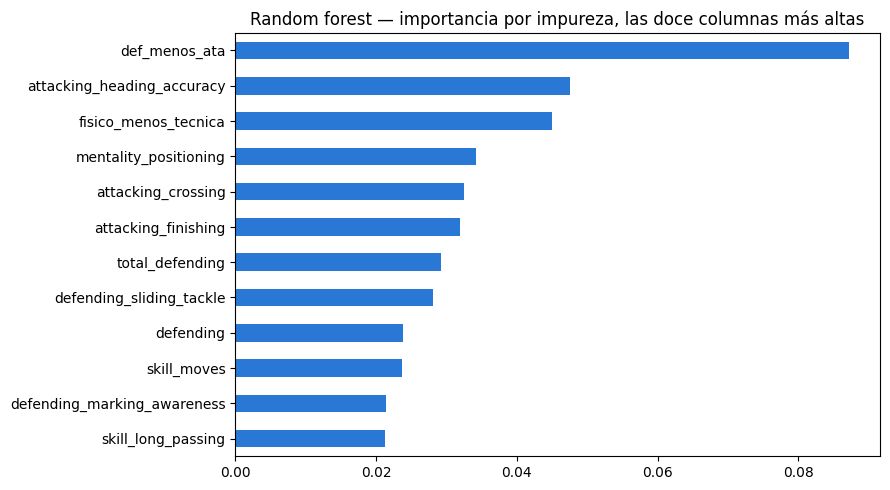

In [ ]:
importancia_bosque = pd.Series(bosque[-1].feature_importances_, index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
importancia_bosque.tail(12).plot.barh(ax=ax, color="#2a78d6")
ax.set_title("Random forest — importancia por impureza, las doce columnas más altas")
plt.tight_layout()
plt.show()

`def_menos_ata` primera, otra vez, y `fisico_menos_tecnica` tercera: las mismas columnas derivadas
que el árbol de la sección 5.2 eligió para sus primeras preguntas, por el mismo motivo. El bosque es
trescientas veces ese árbol.

Pero esta importancia dice menos que un coeficiente, y conviene saber qué le falta:

- **No tiene signo.** Dice que `def_menos_ata` separa roles, no hacia cuál empuja. Para eso hay que
  volver a la matriz de confusión o a los coeficientes.
- **Se calcula sobre el entrenamiento**, no sobre el test. Una columna que el bosque usó para
  memorizar ruido aparece como importante igual.
- **Prefiere las columnas con muchos valores distintos**, porque ofrecen más umbrales donde partir.
  Una categórica de dos valores casi nunca aparece arriba, aunque importe.

Y el gradient boosting tiene un problema anterior: la versión de histogramas que usamos en 4.4
directamente no la expone.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

# qué modelos traen feature_importances_
pd.Series({"RandomForestClassifier":         hasattr(RandomForestClassifier, "feature_importances_"),
           "HistGradientBoostingClassifier": hasattr(HistGradientBoostingClassifier, "feature_importances_"),
           "LogisticRegression":             hasattr(LogisticRegression, "feature_importances_")})

RandomForestClassifier             True
HistGradientBoostingClassifier    False
LogisticRegression                False
dtype: bool

### 5.4 Importancia por permutación: la que sirve para cualquier modelo

Los coeficientes existen sólo en los modelos lineales, el dibujo sólo en los árboles chicos, y la
importancia por impureza sólo en los modelos hechos de árboles — el gradient boosting de
histogramas ni siquiera la expone. Hace falta una que funcione con cualquiera, y la hay: la
importancia por permutación no mira el modelo por dentro. Desordena una columna del test, vuelve a
medir, y la caída de la métrica es la importancia de esa columna. Si barajarla no cambia nada, el
modelo no la estaba usando.

In [ ]:
from sklearn.inspection import permutation_importance

# volvemos a la regresión logística, que es el modelo que estamos explicando
pipeline_completo.set_params(clasificador=LogisticRegression(max_iter=2000)).fit(X_train, y_train)
pi = permutation_importance(pipeline_completo, X_test, y_test, n_repeats=5,
                            scoring="f1_macro", random_state=SEMILLA, n_jobs=-1)

importancia = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
importancia.head(10).round(4)

defending                      0.0959
attacking_heading_accuracy     0.0881
overall                        0.0857
attacking_crossing             0.0837
shooting                       0.0602
defending_sliding_tackle       0.0596
attacking_finishing            0.0505
defending_marking_awareness    0.0503
skill_long_passing             0.0481
mentality_positioning          0.0474
dtype: float64

Se mide **sobre el test y con la métrica que nos importa** (`f1_macro`), así que responde una
pregunta concreta: cuánto f1 por clase perdemos si esa columna se vuelve ruido. `defending` vale
casi diez puntos; `attacking_crossing`, más de ocho — y es coherente con los coeficientes, porque era
la que definía a los extremos.

Notá que el ranking no coincide con el del random forest, y no tiene por qué: es otro modelo,
medido sobre otros datos y con otra métrica. Lo que sí se puede hacer, y es lo que vale para la
Entrega 3, es correr esta misma celda con el pipeline del bosque adentro y comparar.

### 5.5 Lo que la importancia no dice

Hay una trampa clásica, y es mejor verla acá que en la entrega. Comparemos las seis habilidades
agregadas de sofifa.

In [ ]:
importancia[["defending", "shooting", "dribbling", "physic", "passing", "pace"]].round(4)

defending    0.0959
shooting     0.0602
dribbling    0.0418
physic       0.0257
passing      0.0169
pace         0.0127
dtype: float64

In [ ]:
# qué tan parecidas son las dos que quedaron abajo
X[["passing", "dribbling"]].corr().round(3)

,passing,dribbling
passing,1.000,0.864
dribbling,0.864,1.000


`passing` aparece con una importancia de 0,017, menos de la mitad que `dribbling`. La
conclusión fácil sería «el pase no importa para la posición», y es falsa: las dos columnas
correlacionan 0,86. Cuando la permutación arruina `passing`, el modelo se apoya en `dribbling`
y casi no pierde nada — así que lo que mide no es «cuánto importa el pase» sino **cuánto
importa el pase dado que dribbling sigue ahí**.

Con columnas correlacionadas —y en este dataset hay decenas— la importancia se reparte entre las
redundantes y todas parecen prescindibles. La lectura correcta es al revés: una importancia alta
es evidencia fuerte de que la columna aporta; una importancia baja **no** es evidencia de que
no sirva.

## Parte 6 — El puente al proyecto propio

Todo lo de hoy se traslada a tu dataset con muy pocos cambios, y es lo primero que se pregunta
en la Entrega 3.

**Lo que cambia** es la variable objetivo: la tuya no se llama `best_position` y capaz ni
siquiera existe todavía como columna —hay que derivarla, como derivamos los siete roles—. Si es
numérica, tu problema es de regresión y todo lo de hoy vale con `predict` devolviendo un
número.

**Lo que no cambia**, y conviene tener resuelto antes de la entrega:

- **El chequeo de fuga, columna por columna.** Es la tabla que armaste en la Entrega 2. Si una
  columna se completa después del hecho que querés predecir, sale. Medila como medimos
  `player_positions`: comparándola contra la respuesta.
- **El piso.** Un `DummyClassifier` sobre tu dataset. Sin ese número tu accuracy no significa
  nada, y es la primera pregunta que te vamos a hacer.
- **La partición estratificada**, y mirar si alguna clase quedó con menos de un puñado de filas.
- **Una semilla, definida una vez y pasada a todo.** Si tu notebook da un número distinto cada vez
  que se corre, quien corrige no puede saber si el cambio es tuyo o del azar.
- **Un pipeline, no una secuencia de celdas.** Todo lo que le hagas a los datos tiene que estar
  adentro del objeto que entrenás. Si preparás en una celda y entrenás en otra, el día que
  vuelvas a correrlo en otro orden vas a tener el 0,31 de la sección 2.5 sin enterarte.
- **Si escribís un paso propio**, que herede de `BaseEstimator` y `TransformerMixin`, con
  `get_feature_names_out`. La sección 2.7 es el molde.
- **La lectura por clase**, no sólo el promedio, y las matrices de confusión normalizadas en las dos direcciones.
- **Una explicación de en qué se apoya el modelo**: coeficientes con su signo, o importancias, y si lo que
  dicen tiene sentido en tu dominio. Si la columna más importante te sorprende, sospechá de una
  fuga antes de festejar.

Y antes que a tu dataset, se traslada al **TP3**: el mismo canónico, otro objetivo —si un jugador
es titular, suplente o reserva en su club— y una tabla en Kaggle que te dice cuánto acertaste. La
línea de la cátedra en esa tabla es exactamente el pipeline de la sección 3.4 con el objetivo
cambiado; todo lo que la supere sale de pensar el problema, y de lo que viene en la Práctica 2.

## Cierre

La unidad arrancó con una librería de doscientos objetos y termina, por hoy, con tres verbos, un
pipeline armado y un modelo que se puede explicar. Eso es todo lo que hace falta saber de
scikit-learn como herramienta: lo que viene ahora son decisiones, no sintaxis.

Y quedaron tres preguntas abiertas que no son menores: **el modelo más simple le ganó a los dos
más sofisticados**, **la clase Extremo casi no se predice**, y **todos los números de hoy son los de
una sola partición**, la de la semilla 42. La Práctica 2 empieza ahí — por
qué pasa lo primero, cómo se mide de verdad si un modelo es mejor que otro, y qué se hace con
una clase que el modelo entiende pero no contesta.

> Este notebook termina acá. La Práctica 2 es un archivo aparte y vuelve a cargar el dataset
> desde cero: pasan tres semanas entre una clase y la otra, y no conviene depender de que este
> kernel siga vivo.